# Librerias, constantes y cosmologia

In [86]:
import numpy as np
from scipy.integrate import quad

import matplotlib.pyplot as plt

from classy import Class

AS = 2.1E-9
H = 0.7
H0 = 100 * H  # km/s/Mpc

OMATERIA = 0.3
ZEQ = 1300

KEQ = np.sqrt(2 * OMATERIA * H0**2 * (1 + ZEQ)) # km/s/Mpc
ALPHA = (2 / 5 / OMATERIA / 100**2)*2 # (Mpc*s/km)^4

params = {
    # ΛCDM (Planck 2018)
    'h': 0.6736,              # H0 = 100 h km/s/Mpc
    'omega_b': 0.02237,       # Ω_b h²
    'omega_cdm': 0.1200,      # Ω_cdm h²
    'A_s': 2.1e-9,            # amplitud del espectro primordial
    'n_s': 0.9649,            # índice espectral
    'tau_reio': 0.0544,       # profundidad óptica de reionización
    # qué calcular
    'output': 'mPk',          # espectro de potencia de materia
    'P_k_max_1/Mpc': 10.0,    # k máximo [1/Mpc]
    'z_max_pk': 5.0,          # z máximo para P(k,z)
}

cosmo = Class()
cosmo.set(params)
cosmo.compute()

# Obtengo paŕametros que me interesen:
h = cosmo.h()

# Item $(b)$

**Aclaración**: realmente la integral debería ir hasta $\infty$, pero cuando definimos `params` en la key `P_k_max_1/Mpc`, estamos diciendo que como mucho el código acepte hasta $k = 10$.

In [87]:
def sigmaR(R):
    W = lambda x: 3*(np.sin(x) - x*np.cos(x))/x**3
    Delta_lin2 = lambda k, z: cosmo.pk_lin(k, z) * (k)**3 / (2*np.pi**2)

    argumento_int = lambda k: Delta_lin2(k, z = 0) * W(k*R)**2 / k

    return np.sqrt(quad(argumento_int, 0, 5)[0])



print('σ8 Integral:', sigmaR(8/h))
print('σ8 Class:', cosmo.sigma8())


σ8 Integral: 0.8229089022725656
σ8 Class: 0.8229091030815184


Ahora visualizo el integrando de $\sigma_8$:

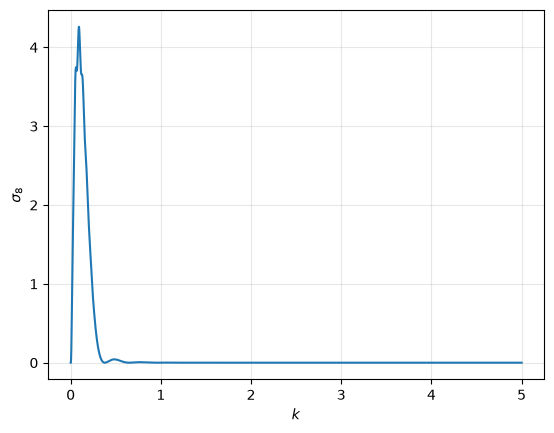

In [88]:
R = 8/h

W = lambda x: 3*(np.sin(x) - x*np.cos(x))/x**3
Delta_lin2 = lambda k, z: cosmo.pk_lin(k, z) * (k)**3 / (2*np.pi**2)
argumento_int = lambda k: Delta_lin2(k, z = 0) * W(k*R)**2 / k


k = np.logspace(-4, np.log10(5), 10_000) # Mismos que el límite de integración
fig, ax = plt.subplots()

y = [argumento_int(_) for _ in k]
ax.plot(k, y)
ax.set(ylabel = r'$\sigma_8$', xlabel = r'$k$')
ax.grid(alpha = .3)

fig.savefig('integracion_sigma8.png', bbox_inches = 'tight')
plt.show()

Ahora realizo una figura correspondiente a $\sigma_8$

/tmp/ipykernel_9527/2955889127.py:7: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  return np.sqrt(quad(argumento_int, 0, 5)[0])
/tmp/ipykernel_9527/2955889127.py:7: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  return np.sqrt(quad(argumento_int, 0, 5)[0])


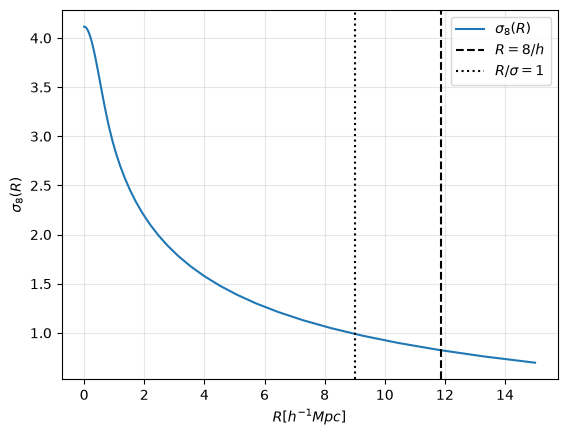

In [89]:
Rs = np.logspace(-4, np.log10(15), 100)

fig, ax = plt.subplots()

ax.plot(Rs, [sigmaR(r) for r in Rs], label = r'$\sigma_8(R)$')
ax.axvline(8/h, linestyle = '--', color = 'k', label = r'$R = 8/h$')
ax.axvline(9, linestyle = ':', color = 'k', label = r'$R / \sigma = 1$')

ax.set(ylabel = r'$\sigma_8(R)$', xlabel = r'$R [h^{-1}Mpc]$')
ax.grid(alpha = .3), ax.legend(loc = 'upper right')

fig.savefig('sigma8enR.png', bbox_inches = 'tight')


# Item $(c)$

Computo el valor de $S_8$ previo al cambio del valor de $\Omega_c$ para no tener que rehacer todas las cuentas

In [90]:
s8 = lambda sigma, omega: sigma*np.sqrt(omega/.3)
s8_1 = s8(cosmo.sigma8(), cosmo.get_current_derived_parameters(['Omega_m'])['Omega_m'])

Lo primero que me piden es que actualice el parámetro $\Omega_c h^2$ a un $20'\%$ menos de su valor asignado al principio, manteniendo fijos $\mathcal{A_s}$, $h$ y $\Omega_b h^2$. En base a esto obtener los nuevos valores de $\sigma_8$ y $\Omega_m$.

In [91]:
cosmo.set({**params, 'omega_cdm': params['omega_cdm']*.2})
cosmo.compute()

values = cosmo.get_current_derived_parameters(['Omega_m', 'sigma8'])
print('Nuevo Ωm = ', values['Omega_m'])
print('Nuevo σ8 = ', values['sigma8'])

Nuevo Ωm =  0.10219577439757167
Nuevo σ8 =  0.23579169958856913


Con estos valores calculo $S_8$ para ambos casos de valores $\Omega_c$

In [92]:
s8_2 = s8(values['Omega_m'], values['sigma8'])

print('Con Ωc normal, S8 = ', s8_1)
print('Con 20% de Ωc, S8 = ', s8_2)

Con Ωc normal, S8 =  0.8415858080524815
Con 20% de Ωc, S8 =  0.09060174618171041
